# 03 · Q-learning (learning from experience, off-policy)

**In this notebook**
- How Q-learning learns, with its update rule explained in plain words.
- **Learning curves** averaged over 20 training runs (seeds): reward and test success rate as training goes on.
- When the agent reaches **stable performance** (the shortest route at several checks in a row).
- The final **policy** (arrows) and **Q-values** (colour map).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from frozenlake_rl.config import CONFIG
from frozenlake_rl import env as fl, plotting as plot
from frozenlake_rl.experiments import load_vi, load_td, q_table
from frozenlake_rl.evaluate import greedy_policy, mean_and_ci, seeds_on_time_grid

plot.apply_style()
pd.set_option("display.precision", 3)
MAPS = list(CONFIG["maps"])          # ["4x4", "8x8"]
RERUN = False                        # True = ignore cached CSVs in results/ and recompute

METHOD = "Q-learning"
COLOR = plot.COLORS[METHOD]

## How it works

**Q-learning** learns by trial and error. It doesn't know the map. It walks around, sees what happens, and slowly
learns how good each action is in each square.

### The update rule

```
new Q(s, a)  =  old Q(s, a)  +  alpha × ( target  −  old Q(s, a) )

target  =  r  +  gamma × (biggest Q(s', a') over all actions a' in the next square)
```

In words: *after each step, move our guess a little towards "the reward we just got + the value of the best thing we
could do next".*

- **Q(s, a)**: our guess of the total future reward for taking action **a** in square **s** and playing well afterwards.
  The table of all Q-values is called the **Q-table** (one row per square, one column per action).
- **r**: the reward we just got.
- **s'**: the square we landed in.
- **biggest Q(s', a')**: the value of the *best* action in the next square, **even if the agent won't actually take it**
  (because sometimes it explores). This makes Q-learning **off-policy**: it learns about the best behaviour
  while actually behaving a bit differently.
- **alpha** (learning rate, 0.1): how big each change is. 0.1 means "move 10% of the way towards the target".
- **gamma** (0.99): how much future reward is worth compared with reward now.
- If s' is a hole or the goal, the episode is over and the target is just **r**.

### Exploring: epsilon-greedy

If the agent always picked the action it currently thinks is best, it might never find a better route.
So with probability **epsilon** it picks a **random** action instead (this is called *exploring*). Otherwise it picks the
best-looking action (*exploiting*). Epsilon starts at 1.0 (always random) and shrinks to 0.01 (random 1% of the time)
over the first half of training. So the agent explores a lot at first and then settles down.

All Q-values start at 0. Every normal step gives −0.01, so actions the agent has tried that led nowhere soon look
*worse* than actions it hasn't tried yet (still 0). This also pushes the agent to try new things.

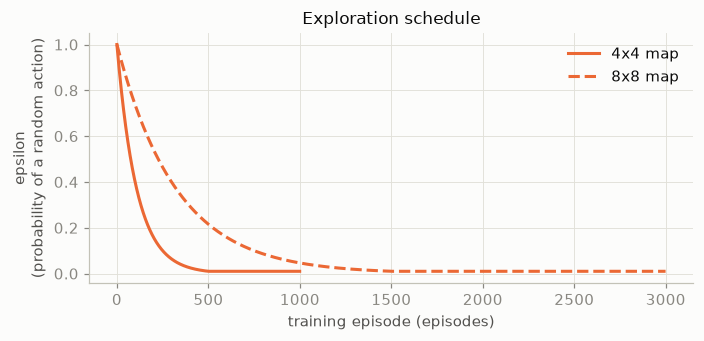

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
from frozenlake_rl.agents import epsilon_at
for m, ls in zip(MAPS, ["-", "--"]):
    cfg = CONFIG["maps"][m]
    ep = np.arange(cfg["n_episodes"])
    ax.plot(ep, [epsilon_at(e, CONFIG["td"]["epsilon_start"], CONFIG["td"]["epsilon_end"], cfg["eps_decay_episodes"])
                 for e in ep], ls, color=COLOR, label=f"{m} map")
ax.set_xlabel("training episode (episodes)"); ax.set_ylabel("epsilon\n(probability of a random action)")
ax.set_title("Exploration schedule"); ax.legend()
plt.tight_layout(); plt.show()

## Training vs testing

- **Training** = the agent explores and updates its Q-table.
- **Testing** = we freeze a copy of the Q-table and follow its **greedy policy**: always the best action, no random moves,
  no updates. A test only measures. It never changes what the agent has learned.

Every 50 training episodes we take a snapshot and test it. This is called a **checkpoint**. The checkpoints give us the
learning curves below without disturbing training. Time spent testing is not counted as training time.

### Where do the differences between runs come from?

The ice is not slippery, and the test policy always picks the same action in the same square. So **every test episode
of a policy gives exactly the same result**, and testing it again tells us nothing new. The randomness is in
**training**: random exploring means each run learns a slightly different Q-table. So we train **20 times with different
random seeds** (a seed fixes the random numbers, so each run can be repeated exactly). We report the **mean** (average)
and the **95% confidence interval** (CI) across the 20 runs.

The 95% CI is the shaded band around each line. Roughly speaking, we are 95% sure the true average lies inside it.
The success rate at a checkpoint is the **percentage of seeds** whose policy reached the goal.

In [3]:
vi = {m: load_vi(m) for m in MAPS}
res = {m: load_td(METHOD, m, rerun=RERUN) for m in MAPS}
optimal = {m: int(vi[m]["summary"]["optimal_steps"].iloc[0]) for m in MAPS}
print("Optimal route length (from Value Iteration):", optimal)

Optimal route length (from Value Iteration): {'4x4': 6, '8x8': 14}


## Learning curves

**Top:** the total reward of each **training** episode, averaged over 25 episodes to smooth it out. It includes the
random exploring moves, so it stays below the best possible value while epsilon is high.
**Middle:** the success rate of the frozen greedy policy at each checkpoint (testing).
**Bottom:** the route length of the greedy policy, for the seeds that reached the goal. The dashed line is the shortest possible route.

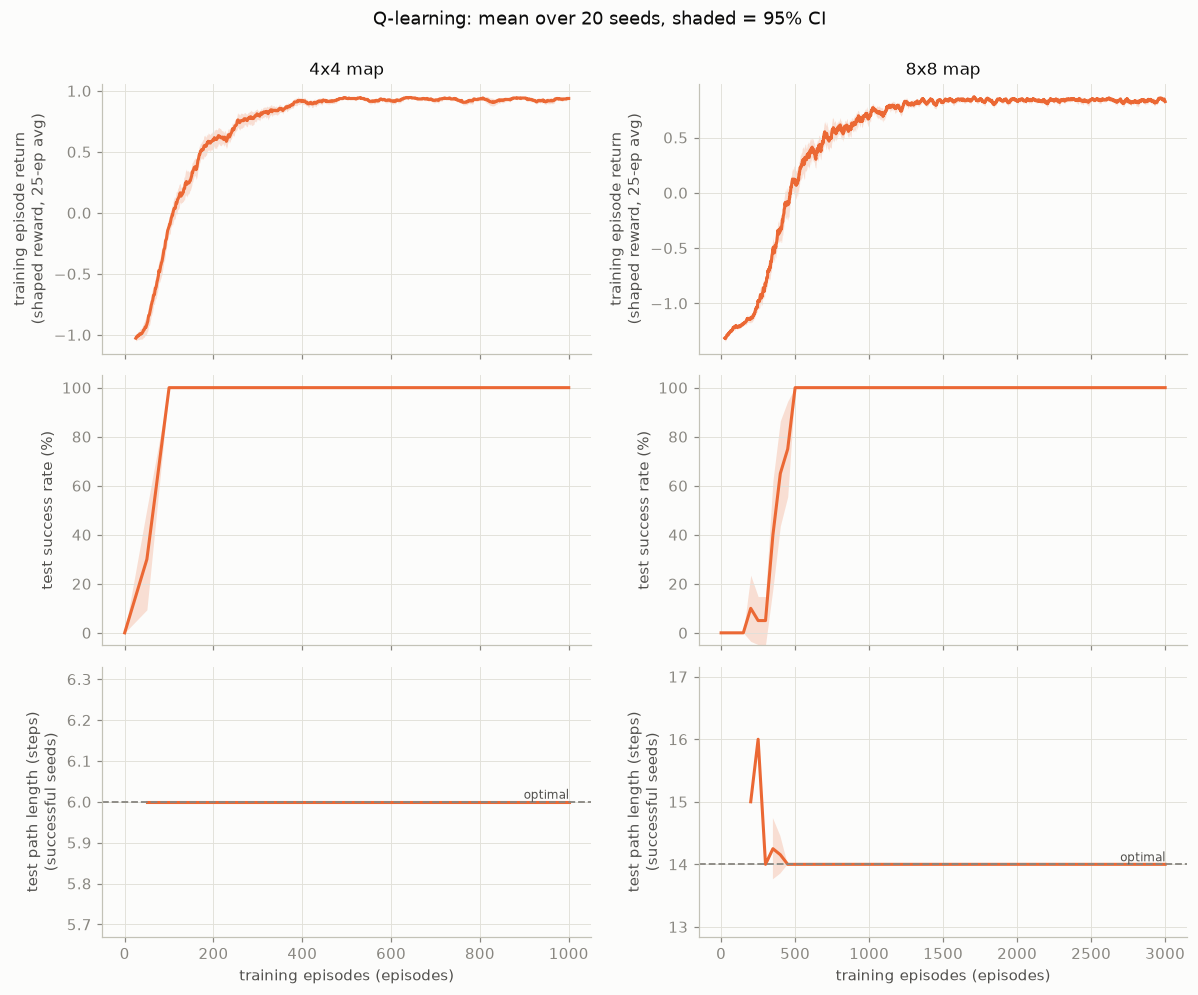

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex="col")
for col, m in enumerate(MAPS):
    ep_x, ret = plot.seeds_matrix(res[m]["episodes"], "episode", "return")
    w = 25
    plot.band(axes[0, col], ep_x[w - 1:], plot.smooth(ret, w), COLOR, METHOD)
    axes[0, col].set_ylabel("training episode return\n(shaped reward, 25-ep avg)")
    axes[0, col].set_title(f"{m} map")

    cp_x, succ = plot.seeds_matrix(res[m]["checkpoints"], "episode", "success_rate")
    plot.band(axes[1, col], cp_x, succ, COLOR, METHOD)
    axes[1, col].set_ylim(-5, 105); axes[1, col].set_ylabel("test success rate (%)")

    _, length = plot.seeds_matrix(res[m]["checkpoints"], "episode", "path_length")
    plot.band(axes[2, col], cp_x, length, COLOR, METHOD)
    axes[2, col].axhline(optimal[m], color=plot.INK_MUTED, ls="--", lw=1.2)
    axes[2, col].text(cp_x[-1], optimal[m], "optimal", ha="right", va="bottom", fontsize=8, color=plot.INK_SECONDARY)
    axes[2, col].set_ylabel("test path length (steps)\n(successful seeds)")
    axes[2, col].set_xlabel("training episodes (episodes)")
fig.suptitle(f"{METHOD}: mean over {len(CONFIG['seeds'])} seeds, shaded = 95% CI", y=1.0)
plt.tight_layout(); plot.save_fig(fig, "03_q_learning_learning_curves"); plt.show()

## Stable performance

We say performance is **stable** when the greedy policy reaches the goal **by the shortest route** at
**5 checkpoints in a row**. The table shows when that first happened, in this method's own units:
training episodes, Q-value updates and training time. One Q-value update = one step of experience.
If any seeds never got there, the table says so.

In [5]:
rows = {}
for m in MAPS:
    st = res[m]["stable"]
    reached = st[st["reached"]]
    def fmt(col, scale=1, digits=0):
        mean, std, _ = mean_and_ci(reached[col] * scale)
        return f"{mean:,.{digits}f} ± {std:,.{digits}f}" if len(reached) else "never reached"
    rows[m] = {"seeds that became stable": f"{len(reached)} / {len(st)}",
               "episodes (mean ± std)": fmt("episode"),
               "Q-value updates (mean ± std)": fmt("q_updates"),
               "training time, ms (mean ± std)": fmt("train_time_s", 1000, 1),
               "training budget (episodes)": CONFIG["maps"][m]["n_episodes"]}
pd.DataFrame(rows)

,4x4,8x8
seeds that became stable,20 / 20,20 / 20
episodes (mean ± std),285 ± 24,628 ± 55
Q-value updates (mean ± std),"1,978 ± 171","12,406 ± 895"
"training time, ms (mean ± std)",12.5 ± 1.2,75.2 ± 14.7
training budget (episodes),1000,3000


## Final test results (after all training episodes)

Each seed's final greedy policy was tested 10 times. Every test gave the same result, as explained above.

In [6]:
rows = {}
for m in MAPS:
    per_seed = res[m]["test"].groupby("seed").agg(success=("success", "mean"), steps=("steps", "mean"),
                                                   ret=("return", "mean"))
    ok = per_seed[per_seed["success"] == 1]
    s_mean, _, s_ci = mean_and_ci(100 * per_seed["success"])
    rows[m] = {"success rate % (mean ± 95% CI)": f"{s_mean:.1f} ± {s_ci:.1f}",
               "path length, steps (successful seeds)": f"{ok['steps'].mean():.2f} ± {ok['steps'].std(ddof=1) if len(ok) > 1 else 0:.2f}",
               "seeds on the optimal route": f"{(ok['steps'] == optimal[m]).sum()} / {len(per_seed)}",
               "return (mean ± std)": f"{per_seed['ret'].mean():.3f} ± {per_seed['ret'].std(ddof=1):.3f}",
               "failed seeds": int((per_seed["success"] < 1).sum())}
pd.DataFrame(rows)

,4x4,8x8
success rate % (mean ± 95% CI),100.0 ± 0.0,100.0 ± 0.0
"path length, steps (successful seeds)",6.00 ± 0.00,14.00 ± 0.00
seeds on the optimal route,20 / 20,20 / 20
return (mean ± std),0.950 ± 0.000,0.870 ± 0.000
failed seeds,0,0


## Final policy and Q-values (seed 0)

**Left:** the greedy policy from the run with seed 0. The shaded line is its route from S.
Squares the agent **never visited** keep their starting Q-values (all 0). Their arrow just points left (the tie-break rule)
and means nothing. These squares are marked with a small grey dot.

**Right:** the Q-table. Each square is split into four triangles, one for each action (left / down / right / up, pointing
that way). **Blue = good** (positive: leads towards the goal). **Red = bad** (negative: leads towards a hole). Grey ≈ 0.

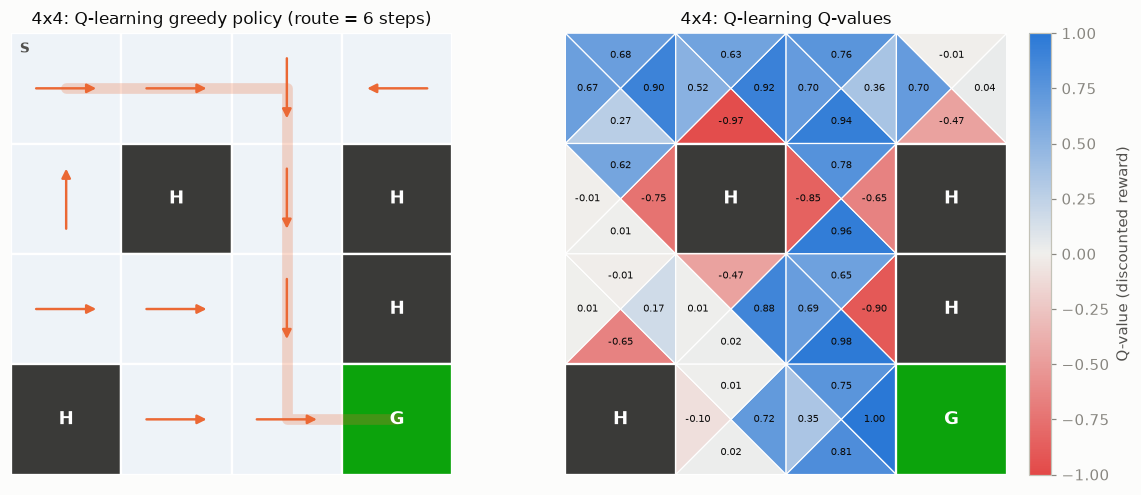

4x4: 0 non-terminal squares never visited by seed 0


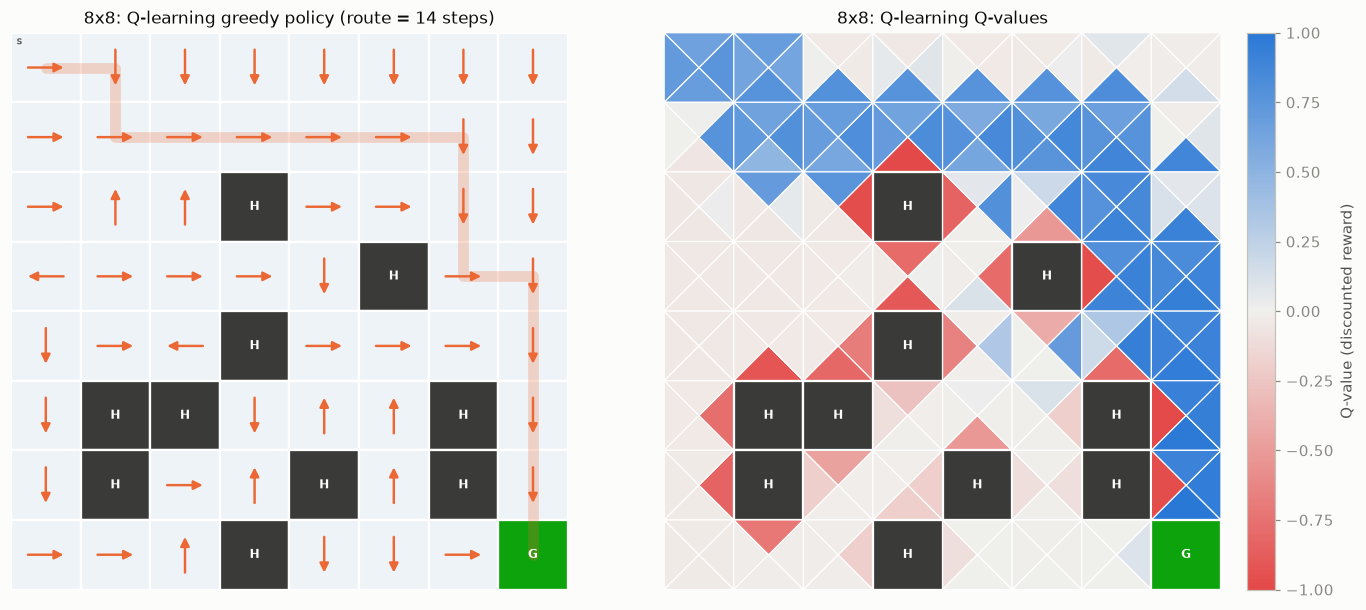

8x8: 0 non-terminal squares never visited by seed 0


In [7]:
SEED = CONFIG["seeds"][0]
for m in MAPS:
    env = fl.make_env(m); t, shape = fl.tiles(env), fl.grid_shape(env)
    Q = q_table(res[m]["qtables"], SEED)
    policy = greedy_policy(Q)
    path = fl.follow_policy(env, policy)
    size = (11, 4.6) if m == "4x4" else (13, 5.6)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=size)
    plot.draw_policy(a1, t, shape, policy, path=path, color=COLOR,
                     title=f"{m}: {METHOD} greedy policy (route = {len(path) - 1} steps)")
    unvisited = [s for s in range(len(t)) if t[s] not in "GH" and np.all(Q[s] == CONFIG["td"]["q_init"])]
    for s in unvisited:
        a1.plot(s % shape[1] + 0.35, s // shape[1] + 0.35, "o", color=plot.INK_MUTED, ms=4)
    plot.draw_q_triangles(a2, t, shape, Q, title=f"{m}: {METHOD} Q-values")
    plt.tight_layout(); plot.save_fig(fig, f"03_q_learning_policy_q_{m}"); plt.show()
    print(f"{m}: {len(unvisited)} non-terminal squares never visited by seed {SEED}")

## Key points

- Q-learning learns the shortest route on both maps without being given the map. All 20 seeds found it.
- It became stable after about **285 episodes on 4x4** and **630 on 8x8**. That is far more work than Value Iteration's
  7 and 15 sweeps, because it has to *discover* where the holes and the goal are by walking around.
- The runs differ a little from seed to seed (the shaded bands), because exploring is random.
- Q-learning learns the value of the *best* action, even while it is still making random moves. So its Q-values describe the greedy route, not the random moves it makes during training.
- Squares far from the route are rarely visited, so their arrows can look strange. This doesn't matter for reaching the goal from S.

Notebook 05 compares Q-learning with SARSA and Value Iteration directly.